# Z24: detección temprana de daño, paso a paso

Este notebook sigue el orden en que se tomaron las decisiones. Cada paso muestra un análisis y la decisión que sale de él.

**Objetivo:** detectar el daño del puente lo antes posible a partir de sus frecuencias naturales, sin confundir con daño los cambios que produce la temperatura.

**Principio:** todo se desarrolla como si no se tuviera información del daño, porque en un puente real solo se conoce el comportamiento del puente sano. Los datos con daño se usan solo para evaluar, al final.

**Índice**
1. [Frecuencias frente a la temperatura](#sec1)
2. [Preparación del daño](#sec2)
3. [División de los datos y validación](#sec3)

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

# Fixed seed, so that any random result is always the same
SEED = 42
np.random.seed(SEED)

# Input files (in the parent folder, bridge-z24)
FREQUENCIES_FILE = "../results/ems_natural_frequencies.csv"
ENVIRONMENT_FILE = "../cache/ems_inventory.csv"

# Important dates
PREP_START = pd.Timestamp("1998-08-05")           # start of the installation of the pier lowering system
DAMAGE_START = pd.Timestamp("1998-08-11 13:15")   # first pier lowering

MODES = [1, 2, 3]


# Shows a table with its caption above it
def show_table(table, number, caption, decimals=3):
    display(Markdown(f"**Tabla {number}.** {caption}"))
    display(table.style.hide(axis="index").format(precision=decimals))


# Shows a figure with its caption below it
def show_figure(fig, number, caption):
    display(fig)
    plt.close(fig)
    display(Markdown(f"**Figura {number}.** {caption}"))

---
<a id="sec1"></a>
## 1. Frecuencias frente a la temperatura

**Datos:**
- Frecuencias de los modos 1, 2 y 3 ($f_1$, $f_2$, $f_3$), identificadas cada hora en `z24_natural_frequencies_ems.ipynb`.
- Temperatura del pavimento, $T$: promedio de los sensores TP1 y TP2. Los códigos de error del registrador (valores de 100 °C o más) se dejan vacíos.

Solo se miran las mediciones del puente sano, antes del 05.08.1998.

In [2]:
# 1. Frequencies and temperatures (pavement TP and slab TDT)
frequencies = pd.read_csv(FREQUENCIES_FILE, parse_dates=["start"])
temperatures = pd.read_csv(ENVIRONMENT_FILE, usecols=["code", "TP1", "TP2", "TDT1", "TDT2"])

# 2. Error codes of the data logger (for example 3276.7) are replaced by NaN
for column in ["TP1", "TP2", "TDT1", "TDT2"]:
    temperatures.loc[temperatures[column].abs() >= 100, column] = np.nan

# 3. Pavement temperature (T) and slab temperature
temperatures["T"] = temperatures[["TP1", "TP2"]].mean(axis=1)
temperatures["T_slab"] = temperatures[["TDT1", "TDT2"]].mean(axis=1)

# 4. One table with both, in time order
data = pd.merge(frequencies, temperatures[["code", "T", "T_slab"]], on="code", how="left")
data = data.sort_values("start").reset_index(drop=True)

# 5. Healthy bridge: measurements before the damage preparation
healthy = data[data["start"] < PREP_START]

correlation = healthy["T"].corr(healthy["T_slab"])
print(f"Healthy measurements: {len(healthy)}, from {healthy['start'].min():%d.%m.%Y} to {healthy['start'].max():%d.%m.%Y}")
print(f"Correlation between pavement and slab temperature: {correlation:.3f}")

Healthy measurements: 4821, from 10.11.1997 to 04.08.1998
Correlation between pavement and slab temperature: 0.977


La temperatura del pavimento y la de la losa están casi perfectamente correlacionadas, así que dan la misma información. Se usa la del **pavimento**.

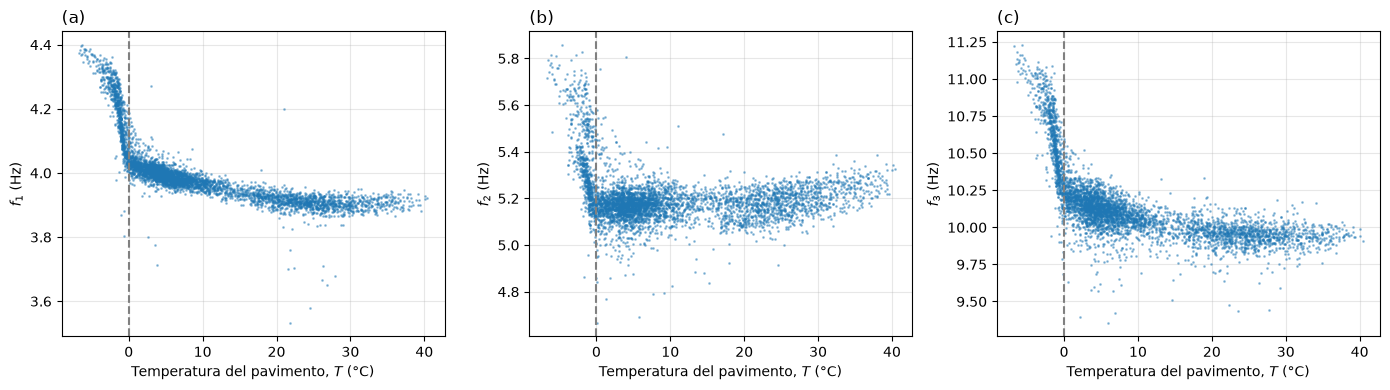

**Figura 1.** Frecuencia frente a la temperatura del pavimento, puente sano (10.11.1997 al 04.08.1998): (a) modo 1, (b) modo 2 y (c) modo 3. La línea discontinua marca 0 °C.

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].plot(healthy["T"], healthy["f1"], ".", markersize=2, alpha=0.4)
axes[1].plot(healthy["T"], healthy["f2"], ".", markersize=2, alpha=0.4)
axes[2].plot(healthy["T"], healthy["f3"], ".", markersize=2, alpha=0.4)

axes[0].set_ylabel("$f_1$ (Hz)")
axes[1].set_ylabel("$f_2$ (Hz)")
axes[2].set_ylabel("$f_3$ (Hz)")
axes[0].set_title("(a)", loc="left")
axes[1].set_title("(b)", loc="left")
axes[2].set_title("(c)", loc="left")
for ax in axes:
    ax.axvline(0, color="gray", linestyle="--")     # 0 °C
    ax.set_xlabel("Temperatura del pavimento, $T$ (°C)")
    ax.grid(alpha=0.3)

fig.tight_layout()
show_figure(fig, 1, "Frecuencia frente a la temperatura del pavimento, puente sano (10.11.1997 al 04.08.1998): "
            "(a) modo 1, (b) modo 2 y (c) modo 3. La línea discontinua marca 0 °C.")

**Qué se ve:**

- **Sobre 0 °C:** las frecuencias bajan poco a poco al subir la temperatura ($f_1$, de unos 4.05 Hz a 0 °C a 3.90 Hz a 30 °C). $f_2$ casi no cambia.
- **Bajo 0 °C:** las tres suben con fuerza ($f_1$ hasta 4.4 Hz, $f_2$ hasta 5.8 Hz, $f_3$ hasta 11.2 Hz). El asfalto se congela y rigidiza el tablero.
- **Dispersión bajo 0 °C:** con la misma temperatura, la frecuencia cambia mucho (por ejemplo, $f_2$ entre 5.2 y 5.8 Hz a −2 °C). La temperatura del momento no basta: importa también cuánto tiempo lleva el puente con frío.
- **Puntos aislados** lejos de la nube: errores de identificación de la frecuencia. Se conservan, porque el monitoreo real también los tendrá.

**Consecuencia:** la relación no es lineal y tiene un quiebre en 0 °C. El modelo necesitará algo más que la temperatura del momento.

---
<a id="sec2"></a>
## 2. Preparación del daño

Del 05.08.1998 al primer descenso de la pila (11.08.1998, 13:15) se instaló el sistema para bajarla: se cortaron tres tramos de la pila Koppigen y se reemplazaron por piezas de acero con gatos hidráulicos (Tabla 2 de `z24_modal_distributions.ipynb`). Son trabajos planificados, así que sus fechas se conocerían también en un puente real.

¿Cambiaron las frecuencias? Se marcan esas mediciones sobre la nube del puente sano (Figura 2) y en el tiempo (Figura 3).

Preparation measurements: 158


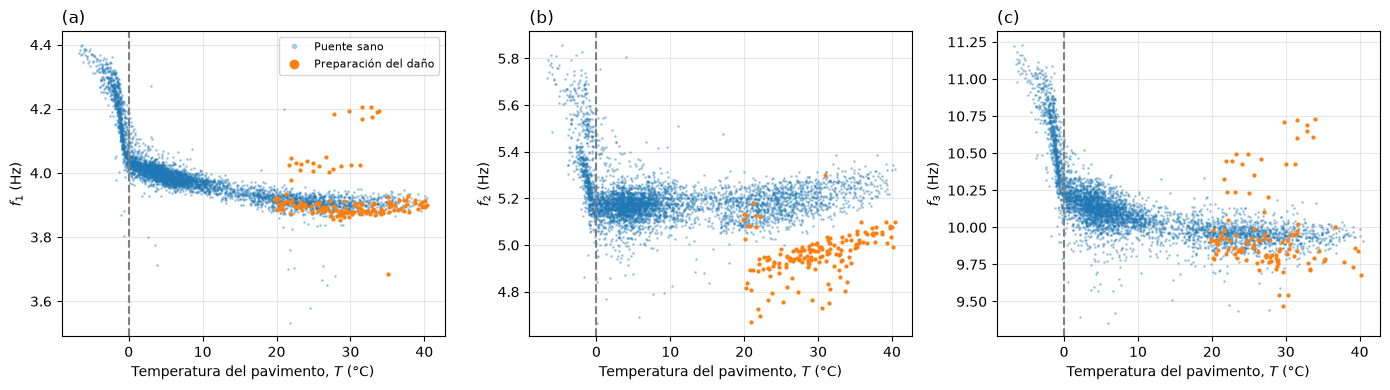

**Figura 2.** Mediciones de la preparación del daño (naranja, 05.08.1998 al 11.08.1998, 13:15) sobre las del puente sano (azul): (a) modo 1, (b) modo 2 y (c) modo 3.

In [4]:
# Measurements of the damage preparation
preparation = data[(data["start"] >= PREP_START) & (data["start"] < DAMAGE_START)]
print(f"Preparation measurements: {len(preparation)}")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for i in range(3):
    column = f"f{MODES[i]}"
    axes[i].plot(healthy["T"], healthy[column], ".", markersize=2, alpha=0.3, color="tab:blue", label="Puente sano")
    axes[i].plot(preparation["T"], preparation[column], ".", markersize=4, color="tab:orange",
                 label="Preparación del daño")
    axes[i].axvline(0, color="gray", linestyle="--")
    axes[i].set_xlabel("Temperatura del pavimento, $T$ (°C)")
    axes[i].set_ylabel(f"$f_{MODES[i]}$ (Hz)")
    axes[i].set_title(["(a)", "(b)", "(c)"][i], loc="left")
    axes[i].grid(alpha=0.3)
axes[0].legend(markerscale=3, fontsize=8)

fig.tight_layout()
show_figure(fig, 2, "Mediciones de la preparación del daño (naranja, 05.08.1998 al 11.08.1998, 13:15) sobre las del "
            "puente sano (azul): (a) modo 1, (b) modo 2 y (c) modo 3.")

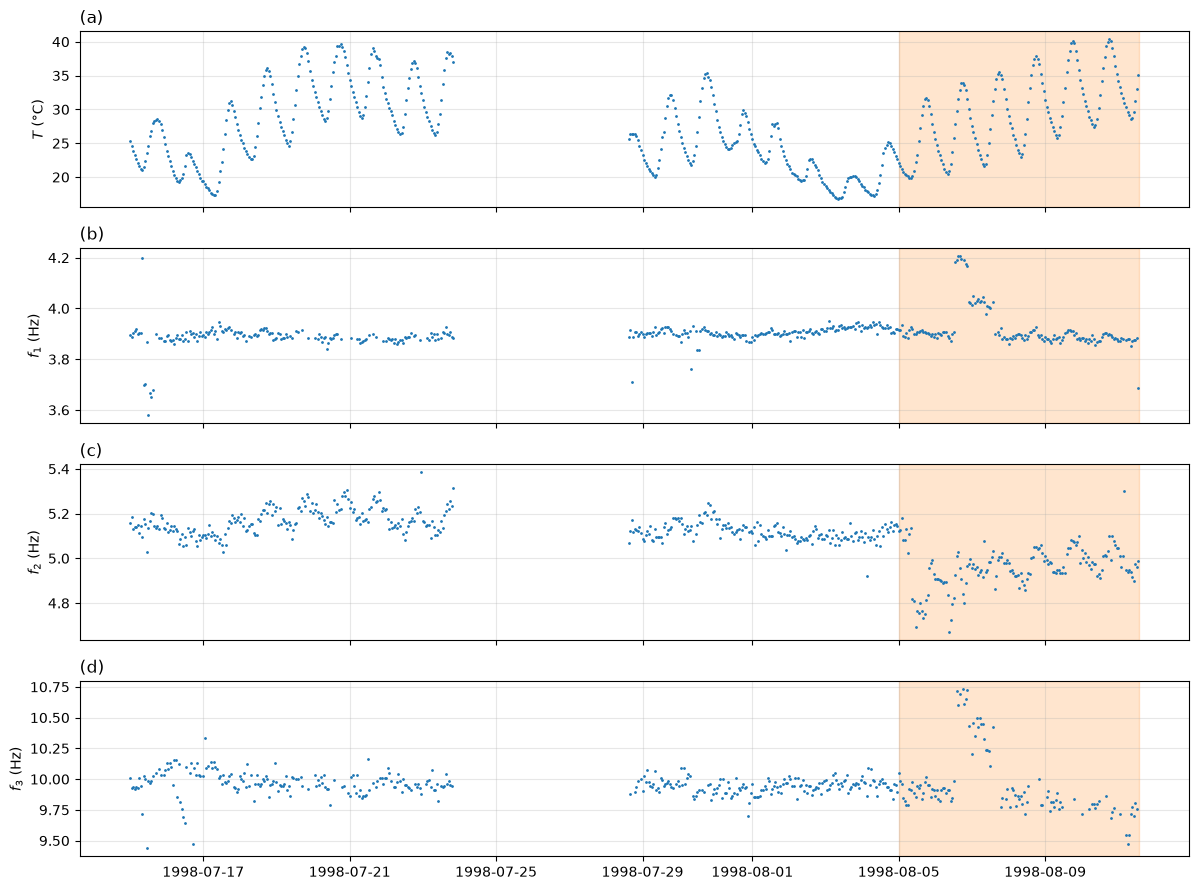

**Figura 3.** Del 15.07.1998 al primer descenso de la pila: (a) temperatura del pavimento, (b) $f_1$, (c) $f_2$ y (d) $f_3$. La franja naranja es la preparación del daño.

In [5]:
# Three weeks before the preparation and the preparation itself
window = data[(data["start"] >= pd.Timestamp("1998-07-15")) & (data["start"] < DAMAGE_START)]

fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
axes[0].plot(window["start"], window["T"], ".", markersize=2)
axes[1].plot(window["start"], window["f1"], ".", markersize=2)
axes[2].plot(window["start"], window["f2"], ".", markersize=2)
axes[3].plot(window["start"], window["f3"], ".", markersize=2)

axes[0].set_ylabel("$T$ (°C)")
axes[1].set_ylabel("$f_1$ (Hz)")
axes[2].set_ylabel("$f_2$ (Hz)")
axes[3].set_ylabel("$f_3$ (Hz)")
labels = ["(a)", "(b)", "(c)", "(d)"]
for i in range(4):
    axes[i].axvspan(PREP_START, DAMAGE_START, color="tab:orange", alpha=0.2)    # preparation
    axes[i].set_title(labels[i], loc="left")
    axes[i].grid(alpha=0.3)

fig.tight_layout()
show_figure(fig, 3, "Del 15.07.1998 al primer descenso de la pila: (a) temperatura del pavimento, (b) $f_1$, (c) $f_2$ "
            "y (d) $f_3$. La franja naranja es la preparación del daño.")

Para medirlo, se comparan las frecuencias con temperaturas parecidas: las mediciones entre 20 y 35 °C del puente sano y de la preparación.

In [6]:
# Median frequency of the healthy bridge and of the preparation, both between 20 and 35 °C
healthy_warm = healthy[(healthy["T"] >= 20) & (healthy["T"] <= 35)]
preparation_warm = preparation[(preparation["T"] >= 20) & (preparation["T"] <= 35)]

rows = []
for mode in MODES:
    column = f"f{mode}"
    healthy_median = healthy_warm[column].median()
    preparation_median = preparation_warm[column].median()
    rows.append({
        "Modo": mode,
        "Puente sano (Hz)": healthy_median,
        "Preparación (Hz)": preparation_median,
        "Cambio (%)": 100 * (preparation_median - healthy_median) / healthy_median,
    })
print(f"Measurements between 20 and 35 °C: healthy {len(healthy_warm)}, preparation {len(preparation_warm)}")
show_table(pd.DataFrame(rows), 1, "Mediana de la frecuencia con temperatura del pavimento entre 20 y 35 °C: puente "
           "sano y preparación del daño.")

Measurements between 20 and 35 °C: healthy 957, preparation 126


**Tabla 1.** Mediana de la frecuencia con temperatura del pavimento entre 20 y 35 °C: puente sano y preparación del daño.

Modo,Puente sano (Hz),Preparación (Hz),Cambio (%)
1,3.907,3.892,-0.373
2,5.192,4.946,-4.734
3,9.948,9.886,-0.621


**Qué se ve:**

- **$f_2$** baja el mismo 05.08 y se queda debajo de la nube del puente sano durante toda la preparación: −4.7 % a la misma temperatura (Tabla 1, Figura 3c).
- **$f_1$ y $f_3$** suben durante cerca de un día (06–07.08, hasta 4.2 y 10.7 Hz) y después vuelven cerca de sus valores sanos (Figura 3b y 3d).
- Un aumento de masa solo bajaría las frecuencias. Que unas suban y otras bajen indica que cambiaron las **condiciones de apoyo de la pila** mientras se cortaba y se ponían los gatos.

**Decisión:** las 158 mediciones de la preparación no representan al puente sano ni al daño que se busca. Se **excluyen del entrenamiento, de la validación y de la prueba**.

---
<a id="sec3"></a>
## 3. División de los datos y validación

### 3.1 Bloques de entrenamiento y de prueba

El método se tiene que probar en dos situaciones: con el puente sano, donde no debe indicar daño, y con el puente dañado, donde debe indicarlo lo antes posible. El daño empieza el 11.08.1998, en verano. Para probar el puente sano en las mismas condiciones, se reservan las **3 semanas anteriores a la preparación** (15.07 al 04.08.1998). Todo lo anterior es el **entrenamiento**.

Se quitan también las mediciones sin alguna frecuencia o sin temperatura: sin frecuencia no hay nada que comparar, y sin temperatura no se puede predecir.

In [7]:
TEST_START = pd.Timestamp("1998-07-15")           # start of the healthy test block


# 1. Time block of each measurement
def get_block(date):
    if date < TEST_START:
        return "Entrenamiento"
    elif date < PREP_START:
        return "Prueba, puente sano"
    elif date < DAMAGE_START:
        return "Preparación del daño"
    else:
        return "Prueba, con daño"


data["block"] = data["start"].apply(get_block)

# 2. Valid measurements: the three frequencies and the temperature, and not in the preparation
complete = data["f1"].notna() & data["f2"].notna() & data["f3"].notna() & data["T"].notna()
data["valid"] = complete & (data["block"] != "Preparación del daño")

# 3. Table of the blocks
BLOCK_USE = {
    "Entrenamiento": "Ajustar y comparar los modelos",
    "Prueba, puente sano": "Solo evaluación: no debe indicar daño",
    "Preparación del daño": "Excluida (paso 2)",
    "Prueba, con daño": "Solo evaluación: cuánto tarda en detectar",
}
rows = []
for block in BLOCK_USE:
    block_data = data[data["block"] == block]
    valid_data = block_data[block_data["valid"]]
    rows.append({
        "Bloque": block,
        "Desde": block_data["start"].min().strftime("%d.%m.%Y"),
        "Hasta": block_data["start"].max().strftime("%d.%m.%Y"),
        "Mediciones": len(block_data),
        "Válidas": len(valid_data),
        "T mínima (°C)": block_data["T"].min(),
        "T máxima (°C)": block_data["T"].max(),
        "Uso": BLOCK_USE[block],
    })
show_table(pd.DataFrame(rows), 2, "Bloques de tiempo: fechas, mediciones, mediciones válidas, rango de temperatura "
           "del pavimento y uso.", decimals=1)

**Tabla 2.** Bloques de tiempo: fechas, mediciones, mediciones válidas, rango de temperatura del pavimento y uso.

Bloque,Desde,Hasta,Mediciones,Válidas,T mínima (°C),T máxima (°C),Uso
Entrenamiento,10.11.1997,14.07.1998,4431,4253,-6.7,40.4,Ajustar y comparar los modelos
"Prueba, puente sano",15.07.1998,04.08.1998,390,324,16.8,39.6,Solo evaluación: no debe indicar daño
Preparación del daño,05.08.1998,11.08.1998,158,0,19.9,40.4,Excluida (paso 2)
"Prueba, con daño",11.08.1998,10.09.1998,674,494,14.0,41.5,Solo evaluación: cuánto tarda en detectar


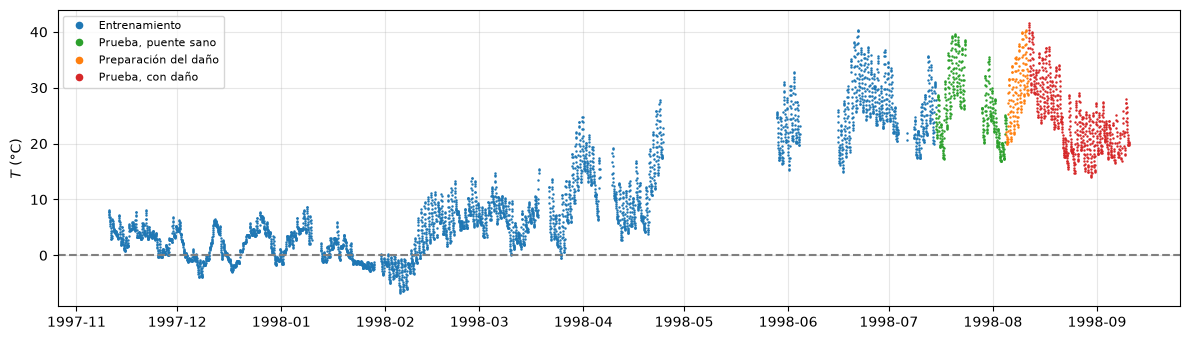

**Figura 4.** Temperatura del pavimento del 10.11.1997 al 10.09.1998, por bloque. La línea discontinua marca 0 °C.

In [8]:
COLORS = {"Entrenamiento": "tab:blue", "Prueba, puente sano": "tab:green",
          "Preparación del daño": "tab:orange", "Prueba, con daño": "tab:red"}

fig, ax = plt.subplots(figsize=(12, 3.5))
for block in BLOCK_USE:
    block_data = data[data["block"] == block]
    ax.plot(block_data["start"], block_data["T"], ".", markersize=1.5, color=COLORS[block], label=block)
ax.axhline(0, color="gray", linestyle="--")
ax.set_ylabel("$T$ (°C)")
ax.legend(markerscale=6, fontsize=8, loc="upper left")
ax.grid(alpha=0.3)

fig.tight_layout()
show_figure(fig, 4, "Temperatura del pavimento del 10.11.1997 al 10.09.1998, por bloque. La línea discontinua marca "
            "0 °C.")

**Qué se ve:**

- El entrenamiento va de noviembre a mediados de julio, con un vacío sin datos en mayo, y cubre de −6.7 a 40.4 °C (Figura 4).
- Las dos pruebas están en verano (14.0 a 41.5 °C), dentro del rango del entrenamiento.
- **Limitación:** las pruebas no tienen helada, así que no evalúan el método en invierno.

### 3.2 ¿Por qué no un k-fold aleatorio?

Para comparar modelos sin tocar la prueba se usa **validación cruzada de $k$ folds**: el entrenamiento se divide en $k$ partes (folds); cada fold se predice con un modelo ajustado con los otros $k-1$, y el error se mide en las predicciones de todos los folds.

En un k-fold aleatorio, cada medición queda en un fold al azar. El problema es que las mediciones son cada hora y una hora se parece mucho a la anterior. Se comprueba prediciendo cada frecuencia con el valor de la hora anterior, sin ningún modelo:

In [9]:
training = data[(data["block"] == "Entrenamiento") & data["valid"]].copy()

# Hours between each measurement and the previous one
hours_since_previous = training["start"].diff().dt.total_seconds() / 3600
consecutive = hours_since_previous <= 1.5

rows = []
for mode in MODES:
    column = f"f{mode}"
    change = training[column].diff()[consecutive]          # frequency minus the one of the previous hour
    rows.append({
        "Modo": mode,
        "Desviación estándar de la frecuencia (Hz)": training[column].std(),
        "Error al copiar la hora anterior (Hz)": np.sqrt(np.mean(change ** 2)),
    })
show_table(pd.DataFrame(rows), 3, "Variación de cada frecuencia en el entrenamiento y error (raíz del error "
           "cuadrático medio) al predecirla con la medición de la hora anterior.")

**Tabla 3.** Variación de cada frecuencia en el entrenamiento y error (raíz del error cuadrático medio) al predecirla con la medición de la hora anterior.

Modo,Desviación estándar de la frecuencia (Hz),Error al copiar la hora anterior (Hz)
1,0.098,0.025
2,0.116,0.068
3,0.247,0.128


- Copiar la hora anterior ya da un error de 0.025 Hz en $f_1$, la cuarta parte de su variación (0.098 Hz).
- En un k-fold aleatorio, casi toda medición de validación tiene a su vecina en el entrenamiento. El error medido sería el de copiar a la vecina, no el de predecir días que el modelo no ha visto. Sería **optimista**.

**Decisión:** los folds se forman con **bloques de tiempo**, no con mediciones sueltas.

### 3.3 Tamaño del bloque

El bloque tiene que ser más largo que los episodios de helada, para no partirlos entre entrenamiento y validación, pero lo bastante corto para que todos los folds tengan helada.

In [10]:
# 1. Frost episodes: consecutive measurements with T below 0 °C (all training measurements, in time order)
training_all = data[data["block"] == "Entrenamiento"]
episode_hours = []
episode_start = None
previous_start = None
for _, row in training_all.iterrows():
    if row["T"] < 0:
        if episode_start is None:
            episode_start = row["start"]
        previous_start = row["start"]
    elif episode_start is not None:
        episode_hours.append((previous_start - episode_start).total_seconds() / 3600)
        episode_start = None
episode_hours = np.array(episode_hours)

print(f"Frost episodes in training: {len(episode_hours)}")
print(f"Longer than 1 day: {(episode_hours > 24).sum()}, longest: {episode_hours.max() / 24:.1f} days")

Frost episodes in training: 24
Longer than 1 day: 8, longest: 8.6 days


Con bloques de un día, 8 episodios quedarían partidos. Las dos opciones razonables son semanas o meses, repartidos por turnos en $k = 5$ folds (bloque 0 → fold 1, bloque 1 → fold 2, ..., bloque 5 → fold 1). Se compara cuántas mediciones bajo 0 °C recibe cada fold:

In [11]:
N_FOLDS = 5
first_date = training["start"].min()

# 1. Weekly blocks: week counted from the first measurement
week = (training["start"] - first_date).dt.days // 7
training["fold"] = week % N_FOLDS + 1

# 2. Monthly blocks, for comparison: month counted from the first month
month = (training["start"].dt.year - first_date.year) * 12 + training["start"].dt.month - first_date.month
monthly_fold = month % N_FOLDS + 1

# 3. Measurements below 0 °C in each fold
below_zero = training["T"] < 0
rows = []
for fold in range(1, N_FOLDS + 1):
    rows.append({
        "Fold": fold,
        "Mediciones (semanas)": (training["fold"] == fold).sum(),
        "Bajo 0 °C (semanas)": ((training["fold"] == fold) & below_zero).sum(),
        "Mediciones (meses)": (monthly_fold == fold).sum(),
        "Bajo 0 °C (meses)": ((monthly_fold == fold) & below_zero).sum(),
    })
print(f"Weeks in training: {week.max() + 1}, months: {month.max() + 1}")
show_table(pd.DataFrame(rows), 4, "Mediciones válidas y mediciones bajo 0 °C de cada fold, con bloques de una "
           "semana y de un mes repartidos por turnos.")

Weeks in training: 36, months: 9


**Tabla 4.** Mediciones válidas y mediciones bajo 0 °C de cada fold, con bloques de una semana y de un mes repartidos por turnos.

Fold,Mediciones (semanas),Bajo 0 °C (semanas),Mediciones (meses),Bajo 0 °C (meses)
1,818,195,932,17
2,842,108,791,272
3,956,206,1036,245
4,802,125,846,187
5,835,91,648,4


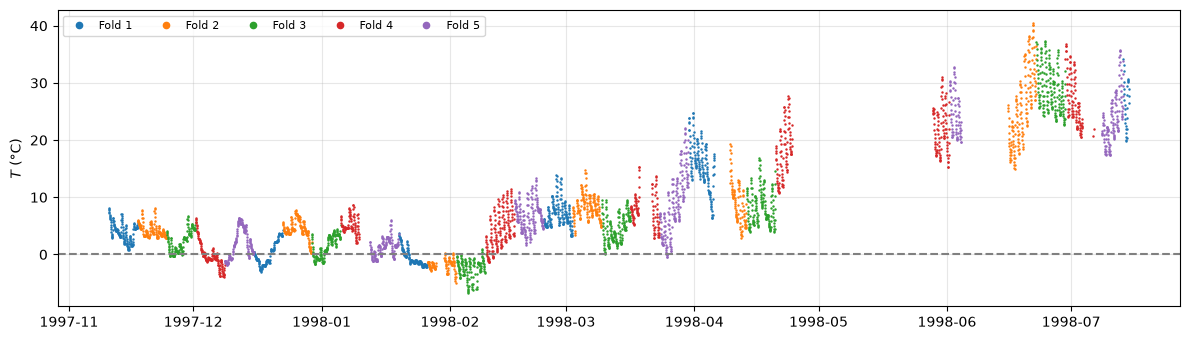

**Figura 5.** Temperatura del pavimento en el entrenamiento, coloreada por fold (bloques de una semana repartidos por turnos). La línea discontinua marca 0 °C.

In [12]:
FOLD_COLORS = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple"]

fig, ax = plt.subplots(figsize=(12, 3.5))
for fold in range(1, N_FOLDS + 1):
    fold_data = training[training["fold"] == fold]
    ax.plot(fold_data["start"], fold_data["T"], ".", markersize=1.5, color=FOLD_COLORS[fold - 1], label=f"Fold {fold}")
ax.axhline(0, color="gray", linestyle="--")
ax.set_ylabel("$T$ (°C)")
ax.legend(markerscale=6, fontsize=8, ncol=5, loc="upper left")
ax.grid(alpha=0.3)

fig.tight_layout()
show_figure(fig, 5, "Temperatura del pavimento en el entrenamiento, coloreada por fold (bloques de una semana "
            "repartidos por turnos). La línea discontinua marca 0 °C.")

- **Con meses** (Tabla 4), la helada cae casi entera en los folds 2, 3 y 4. Los folds 1 y 5 casi no tienen mediciones bajo 0 °C, así que no medirían el error en invierno.
- **Con semanas**, todos los folds tienen entre 91 y 206 mediciones bajo 0 °C y unas 800 a 950 en total. Cada fold mezcla semanas de invierno y de verano (Figura 5).
- **Limitación:** el episodio más largo (8.6 días) y los que cruzan un cambio de semana sí quedan partidos.

**Decisión:** validación cruzada con **bloques de una semana repartidos por turnos en 5 folds**.

### 3.4 Métrica

Para cada modo $m$ y cada medición $i$, el **residuo** es la diferencia entre la frecuencia medida y la que predice el modelo:

$$
r_{m,i} = f_{m,i} - \hat{f}_{m,i}
\tag{1}
$$

donde $f_{m,i}$ es la frecuencia medida y $\hat{f}_{m,i}$ la predicha por un modelo ajustado sin el fold de la medición $i$.

El error del modelo es la **raíz del error cuadrático medio** (RMSE), en Hz:

$$
\text{RMSE} = \sqrt{\frac{1}{n} \sum_{i=1}^{n} r_{m,i}^2}
\tag{2}
$$

donde $n$ es el número de mediciones.

- Se calcula **por modo**, porque cada frecuencia tiene su propia escala (Tabla 3).
- Se calcula en total, **bajo 0 °C y sobre 0 °C**: la mayor dispersión está bajo 0 °C (Figura 1), pero esas mediciones son solo el 17 % del entrenamiento, así que el RMSE total escondería los errores de invierno.